## **실습 개요**

여러분은 스타트업 투자를 검토하는 벤처캐피탈(VC)의 데이터 분석팀에 합류했습니다. <br>
투자 심사역들은 여러 스타트업의 지출 내역(연구개발비, 관리비, 마케팅비)과 본사 소재지 정보를 바탕으로,<br>
**스타트업의 예상 순이익(Profit)을 예측**하는 모델을 만들어 투자 의사결정에 참고하려고 합니다.

재무팀에서 취합해 넘겨준 데이터에는 입력 실수로 인한 이상치, 결측치, 중복 입력된 행이 섞여 있습니다. <br>
이 데이터를 정제하고 **다중 선형 회귀(Multiple Linear Regression)** 모델을 학습시켜, 새로운 스타트업의 예상 순이익을 예측해봅시다.

## **데이터셋 설명**

여러 스타트업들의 지출 항목별 비용과 순이익에 대한 데이터입니다.

| 컬럼명 | 설명 |
|---|---|
| R&D Spend | 연구개발(R&D)에 지출한 비용 (달러) |
| Administration | 관리 및 운영에 지출한 비용 (달러) |
| Marketing Spend | 마케팅에 지출한 비용 (달러) |
| State | 스타트업 본사가 위치한 주(州) (New York / California / Florida) |
| Profit | **[target]** 스타트업의 순이익 (달러) |

## **데이터셋 URL**

url :https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/startups.csv

## **1. 데이터 살펴보기**

데이터를 불러오고, 각 컬럼이 어떤 의미를 갖는지, 데이터의 전체적인 형태가 어떤지 살펴봅니다.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/startups.csv")
df.head()

,R&D Spend,Administration,Marketing Spend,State,Profit
0,24967.87,141561.98,13309.33,California,56387.42
1,80957.01,171801.30,0.00,California,85070.65
2,59229.85,NaN,35914.66,Florida,57781.05
3,96902.98,120396.70,113669.24,Florida,102467.54
4,NaN,125940.06,149606.63,Florida,73350.78


**Q1. 데이터의 shape(행, 열 개수)을 확인하세요.**

In [3]:
df.shape

(995, 5)

**Q2. 각 컬럼의 기본적인 정보를 확인하세요.**


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 995 entries, 0 to 994
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   R&D Spend        954 non-null    float64
 1   Administration   935 non-null    float64
 2   Marketing Spend  946 non-null    float64
 3   State            995 non-null    str    
 4   Profit           995 non-null    float64
dtypes: float64(4), str(1)
memory usage: 39.0 KB


**Q3. 수치형 컬럼들의 통계 요약을 확인하세요.**

In [5]:
df.describe()

,R&D Spend,Administration,Marketing Spend,Profit
count,954.000000,935.000000,946.000000,995.000000
mean,79363.521446,122429.422820,109843.986649,84893.717839
std,45844.125872,27825.971717,74558.783452,35415.447535
min,-61979.136882,-149983.611198,-39197.266737,8236.520000
25%,46915.627500,104686.440000,57413.237500,59699.580000
50%,72382.655000,123022.140000,105407.225000,80343.630000
75%,104200.502500,140872.580000,156681.112500,106108.385000
max,412182.953748,183000.000000,639768.992471,184672.110000


## **2. 데이터 분석하기**
데이터를 분석하여 인사이트를 찾아내는 과정입니다.
- 각 컬럼이 어떤 의미를 갖는지, 데이터의 전체적인 형태가 어떤지 살펴봅니다.
- 그리고 데이터를 이해하기 위한 여러 정보들을 찾아 csv 형태로 추출하여 채점 사이트에 제출합니다.


### **2-1. 데이터 탐색**


**Q1. 데이터를 분석하여 다음 정보를 찾아 주세요.**

- State별 평균 Profit을 소수점 2자리까지 구하세요.

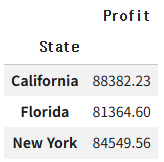

In [6]:
df.groupby("State")["Profit"].mean().round(2)

State
California    88382.23
Florida       81364.60
New York      84549.56
Name: Profit, dtype: float64

In [7]:
# [실습 1번 예시]
result_df = df.groupby("State")["Profit"].mean().round(2)
result_df.to_csv("submission.csv", index=True)

try:
    from google.colab import files
    files.download("submission.csv")
except ImportError:  # colab 이 아닌 로컬 환경
    pass

**Q2. 데이터를 분석하여 다음 정보를 찾아 주세요.**

- R&D Spend 기준 상위 10개 스타트업의 평균 Profit을 소수점 2자리까지 구하세요.
- Marketing Spend가 0 이하인 스타트업의 개수를 구하세요.
- New York에 존재하는 기업의 비율을 백분률로, 소수점 2자리 까지 구하세요.

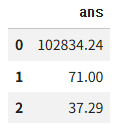

In [33]:
# R&D Spend 기준 상위 10개 스타트업의 평균 Profit
top10_df = df.sort_values("R&D Spend", ascending=False).head(10)
top10_mean = top10_df["Profit"].mean().round(2)
print(f"top10 = {top10_mean}")

top10 = 102834.24


In [34]:
# Marketing Spend가 0 이하인 스타트업의 개수
zero_mkt_count = (df["Marketing Spend"] <= 0).sum()
zero_mkt_count

np.int64(71)

In [36]:
# New York 기업의 비율(%)
ny_ratio = round((df["State"] == "New York").mean() * 100, 2)
ny_ratio

np.float64(37.29)

**Q3. 데이터를 분석하여 다음 정보를 찾아 주세요.**

- 데이터에 존재하는 State별 개수의 분포와 R&D에 활용하는 평균 비용을 소수점 2자리까지 구하세요.

In [37]:
# State별 기업 수 분포와 평균 R&D Spend
state_summary = df.groupby("State").agg(
    count=("State", "size"),
    avg_rnd_spend=("R&D Spend", "mean"),
).round(2)
state_summary

,count,avg_rnd_spend
State,,
California,332,81199.06
Florida,292,78597.13
New York,371,78321.71


### **2-2. 데이터 시각화**

**Q1. Profit의 분포를 히스토그램으로 시각화하세요.**

그리고 이 그래프로서 알 수 있는 정보를 코드 아래에 적어주세요.

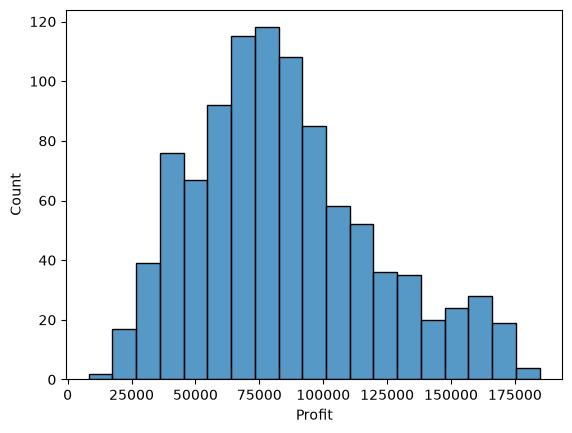

In [12]:
sns.histplot(df["Profit"])
plt.show()

**Q2. R&D Spend와 Profit의 관계를 산점도로 시각화하세요.**

그리고 이 그래프로서 알 수 있는 정보를 코드 아래에 적어주세요.

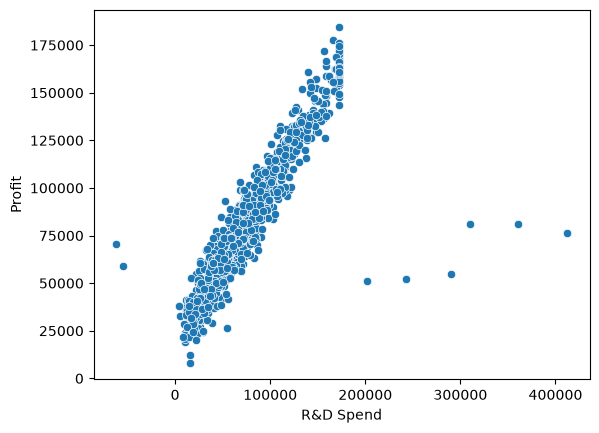

In [13]:
sns.scatterplot(data=df, x="R&D Spend", y="Profit")
plt.show()

**Q3. R&D Spend와 Marketing Spend의 관계를 산점도로 시각화하세요.**

그리고 이 그래프로서 알 수 있는 정보를 코드 아래에 적어주세요.

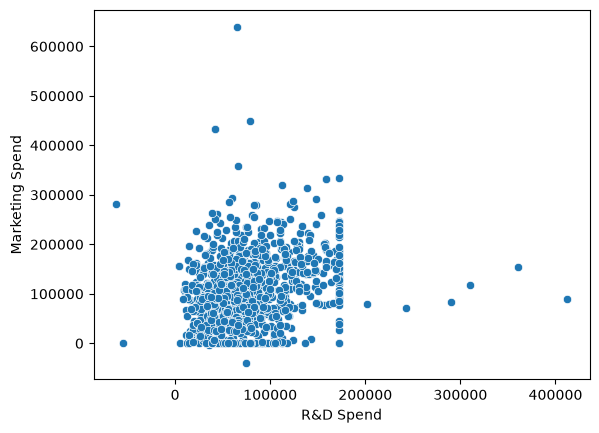

In [14]:
sns.scatterplot(data=df, x="R&D Spend", y="Marketing Spend")
plt.show()

**Q4. State별 Profit을 박스플롯(box plot)으로 비교하세요.**

그리고 이 그래프로서 알 수 있는 정보를 코드 아래에 적어주세요.

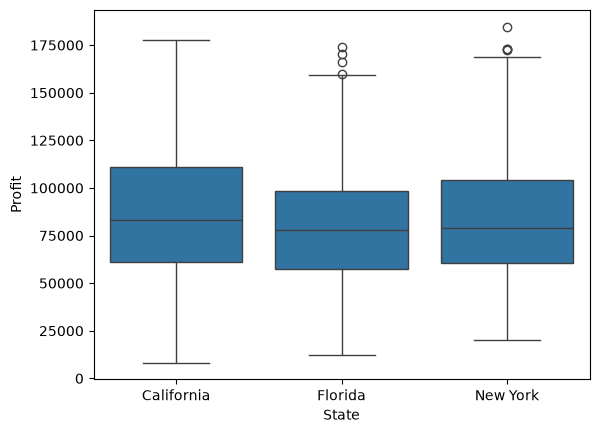

In [15]:
sns.boxplot(data=df, x="State", y="Profit")
plt.show()

# 분석: State 별 중앙값/분포가 크게 다르지 않다
# - State 가 Profit 에 미치는 영향은 크지 않을 것이다.

**Q5. Marketing Spend를 박스플롯으로 확인하세요.**

그리고 이 그래프로서 알 수 있는 정보를 코드 아래에 적어주세요.

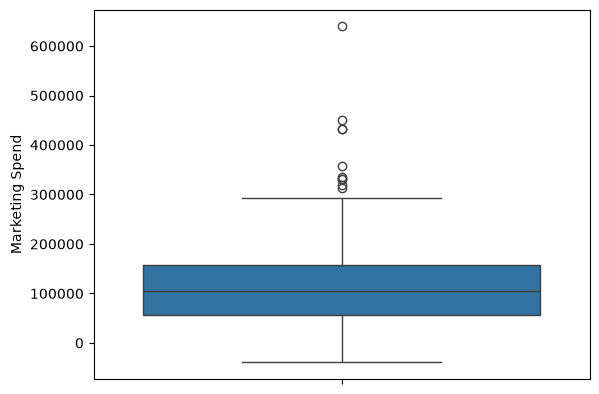

In [16]:
sns.boxplot(y=df["Marketing Spend"])
plt.show()

# 해석: 수염(whisker) 범위 밖의 점들은 IQR 기준 이상치다. 추가적인 전처리가 필요할 가능성이 있다.

## **3. 데이터 전처리하기**

In [17]:
# 데이터를 전처리하다 망가트리면 여기서부터 재시작!
df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/startups.csv")
df.head()

,R&D Spend,Administration,Marketing Spend,State,Profit
0,24967.87,141561.98,13309.33,California,56387.42
1,80957.01,171801.30,0.00,California,85070.65
2,59229.85,NaN,35914.66,Florida,57781.05
3,96902.98,120396.70,113669.24,Florida,102467.54
4,NaN,125940.06,149606.63,Florida,73350.78


### **3-1. 이상치 처리하기 1**

이상치를 해결하는 방법은 2가지가 있습니다.
<br>그 중 첫번째는 그냥 삭제를 해버리는 것입니다.

**Q1. 애초에 말도 안되는 데이터는 제거를 해봅시다.**
- R&D Spend, Administration, Marketing Spend는 음수가 될 수 없습니다. (지출 비용).

일반적으로는, 데이터 학습 및 테스트에 "안 쓰일 데이터"는 추가적인 전처리 과정 전에 먼저 제거를 합니다.

**R&D Spend, Administration, 그리고 Marketing Spend중 하나라도 음수인 행들의 개수를 세어 봅시다.**

In [18]:
cost_cols = ["R&D Spend", "Administration", "Marketing Spend"]

# any(axis=1): 행 단위 OR 조건 (한 컬럼이라도 True 이면 그 행은 True)
# NaN < 0 은 False 이므로 결측치 행은 여기서 걸리지 않는다.
negative_mask = (df[cost_cols] < 0).any(axis=1)
negative_mask.sum()

np.int64(6)

**Q2. 위에 해당하는 행들을 모두 삭제해 봅시다.**

In [19]:
# 음수 행 제거 + 중복 행 제거
df_clean = df[~negative_mask].drop_duplicates().reset_index(drop=True)
print(df.shape, "->", df_clean.shape)
df_clean.tail()

(995, 5) -> (944, 5)


,R&D Spend,Administration,Marketing Spend,State,Profit
939,21674.83,118989.11,106381.94,New York,20095.28
940,92606.98,140876.75,73776.31,Florida,88151.30
941,172000.00,158962.30,100894.81,New York,161088.39
942,107176.98,140660.87,2184.92,California,97657.57
943,105274.65,120149.66,1396.11,California,109702.80


**Q3. 남아있는 음수 값이 없는지 다시 확인해보세요.**

In [20]:
(df_clean[cost_cols] < 0).any(axis=1).sum()

np.int64(0)

### **3-2. 데이터 분리하기**

**Q1. Profit을 target으로 하여 train과 테스트 데이터를 분리합니다.**
- 비율 : 7(학습) : 3(테스트)
- 재현성을 위해 random_state = 101로 설정합니다.

In [21]:
from sklearn.model_selection import train_test_split

X = df_clean.drop(columns="Profit")
y = df_clean["Profit"]

# .copy(): 이후 전처리에서 SettingWithCopyWarning 방지
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)
X_train, X_test = X_train.copy(), X_test.copy()
print(X_train.shape, X_test.shape)

(660, 4) (284, 4)


### **3-3. 결측치 처리하기**

Data Leakage를 방지하기 위해, 모든 학습과 테스트에 전처리되어 사용될 데이터는 학습, 테스트 데이터 분리 이후 진행합니다.

결측치를 채우는 방법은 크게 2가지가 있습니다.
- **평균(Mean)**: 이상치가 없고 데이터가 좌우 대칭(정규분포)일 때 적합합니다.
- **중위수(Median)** : 데이터에 이상치가 있거나, 한쪽으로 치우친 데이터일 때 안전합니다.

**Q1. train 데이터의 결측치 개수를 확인합니다.**

In [22]:
X_train.isnull().sum()

R&D Spend          26
Administration     37
Marketing Spend    30
State               0
dtype: int64

**Q2. R&D Spend, Administration, Marketing Spend의 결측치를 train 데이터의 중앙값(median)으로 대체하세요.**

이때, test 데이터에도 동일한(train 기준) 값을 사용하세요



In [23]:
# train 기준 중앙값을 train/test 모두에 적용 (data leakage 방지)
train_medians = X_train[cost_cols].median()
X_train[cost_cols] = X_train[cost_cols].fillna(train_medians)
X_test[cost_cols] = X_test[cost_cols].fillna(train_medians)

**Q3. 다시 한번 train 데이터의 결측치 개수를 확인합니다.**

In [24]:
X_train.isnull().sum()

R&D Spend          0
Administration     0
Marketing Spend    0
State              0
dtype: int64

In [25]:
X_test.isnull().sum()

R&D Spend          0
Administration     0
Marketing Spend    0
State              0
dtype: int64

### **3-4. 이상치 처리하기 2**

이상치를 해결하는 두번째 방법은, clipping (capping, winsorizing)입니다.

**Q1. IQR을 통해 각 column에 outlier가 몇 개씩이나 있는지를 확인해보세요.**

In [26]:
# q1: 하위 25% 지점 / q3: 하위 75% 지점
q1 = X_train[cost_cols].quantile(0.25)
q3 = X_train[cost_cols].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outlier_count = ((X_train[cost_cols] < lower_bound) | (X_train[cost_cols] > upper_bound)).sum()
outlier_count

R&D Spend           4
Administration      4
Marketing Spend    10
dtype: int64

**Q2. IQR 기준을 이용해, 수치형 컬럼의 값을 [Q1 - 1.5 * IQR ~ Q3 + 1.5 * IQR] 범위로 clipping(capping)하세요.**
- 이상치를 제거(행 삭제)하지 않고 범위 내로 눌러주는(capping) 방식을 사용하여 데이터 손실 없이 극단값의 영향을 줄입니다.
- train 기준의 lower/upper bound를 test에도 동일하게 적용하세요.

In [27]:
# lower_bound / upper_bound: train 데이터 기준 이상치 경계 (test 에도 동일하게 적용)
X_train[cost_cols] = X_train[cost_cols].clip(lower=lower_bound, upper=upper_bound, axis=1)
X_test[cost_cols] = X_test[cost_cols].clip(lower=lower_bound, upper=upper_bound, axis=1)

**Q3. 각 컬럼에 이상치가 아직 존재하는지 확인합니다.**

In [28]:
((X_train[cost_cols] < lower_bound) | (X_train[cost_cols] > upper_bound)).sum()

R&D Spend          0
Administration     0
Marketing Spend    0
dtype: int64

**Q4. 캡핑 처리 검증을 위해 boxplot을 다시 한번 그려 봅시다.**

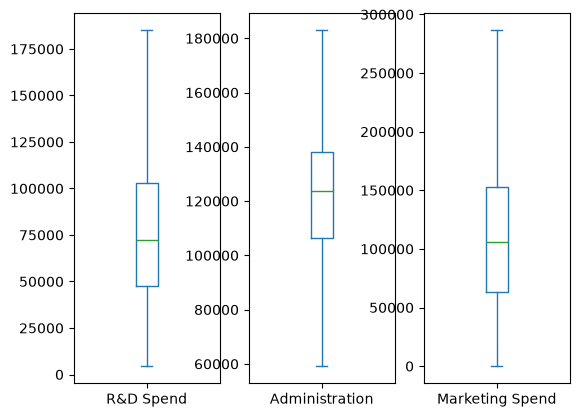

In [29]:
X_train[cost_cols].plot(kind="box", subplots=True)
plt.show()

### **3-5. Feature Encoding**

**Q1. State컬럼을 인코딩하세요.**

State는 순서가 없는 3개 범주(New York / California / Florida)를 갖는 명목형(nominal) 변수이므로, One-Hot Encoding을 활용합니다.

먼저 X_train 데이터의 컬럼을 One-Hot Encoding 해보도록 합시다.

In [30]:
from sklearn.preprocessing import OneHotEncoder

# sparse_output=False: DataFrame 에 바로 쓸 수 있는 dense 배열
# drop="first": 더미 변수 함정(다중공선성) 방지
ohe = OneHotEncoder(sparse_output=False, drop="first")

train_state = pd.DataFrame(
    ohe.fit_transform(X_train[["State"]]),
    columns=ohe.get_feature_names_out(),
    index=X_train.index,
)
X_train_enc = pd.concat([X_train.drop(columns="State"), train_state], axis=1)
X_train_enc

,R&D Spend,Administration,Marketing Spend,State_Florida,State_New York
868,81345.01,123347.63,106263.465,1.0,0.0
83,77784.96,98865.45,133263.810,0.0,1.0
258,54458.20,150716.87,0.000,0.0,0.0
835,14958.54,109950.44,0.000,0.0,1.0
531,76075.48,95385.16,78796.860,1.0,0.0
...,...,...,...,...,...
575,65010.38,114765.40,156794.000,0.0,1.0
838,103254.99,90529.63,0.000,0.0,1.0
337,94362.56,146098.25,194426.230,0.0,1.0
523,95878.36,123688.52,93573.820,0.0,1.0


**Q2. 테스트 데이터의 State 컬럼도 one-hot encoding 해줍니다.**

In [31]:
test_state = pd.DataFrame(
    ohe.transform(X_test[["State"]]),
    columns=ohe.get_feature_names_out(),
    index=X_test.index,
)
X_test_enc = pd.concat([X_test.drop(columns="State"), test_state], axis=1)
X_test_enc

,R&D Spend,Administration,Marketing Spend,State_Florida,State_New York
844,46816.68000,154894.16,123921.80,0.0,0.0
179,75750.21000,134613.19,183208.73,1.0,0.0
323,145208.30000,158947.97,178731.37,1.0,0.0
281,55332.83000,123022.14,34850.01,0.0,1.0
389,185111.08375,152955.62,70721.24,0.0,1.0
...,...,...,...,...,...
767,53223.38000,143022.24,229340.28,0.0,1.0
509,98685.28000,143819.24,169310.85,0.0,1.0
89,44385.08000,123688.52,144416.52,0.0,0.0
886,131234.62000,123161.12,174246.19,0.0,1.0


## **4. 모델 학습 및 평가**

### **4-1. 모델 학습**

**Q1. Linear Regression 모델을 만들고, 학습시키세요.**

In [39]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

model = LinearRegression()
model.fit(X_train_enc, y_train) # local 에서 수행 시 fit 의 출력으로 인해 버그가 납니다.
print("")  # 아무거나 출력하면 버그가 없어집니다.

### **4-2. 예측**

**Q1. 학습된 모델로 test 데이터에 대한 예측값을 구하세요.**

예측값은 y_pred 에 저장합니다.

In [40]:
y_pred = model.predict(X_test_enc)

### **4-3. 모델 평가**

**Q1. MSE, RMSE, R2 Score를 이용해 모델 성능을 평가하세요.**

In [41]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MSE  = {mse:.4f}")
print(f"RMSE = {rmse:.4f}")
print(f"R2   = {r2:.4f}")

# 해석 (재실행 후 실제 수치로 갱신할 것)
# - RMSE: 예측 Profit 이 실제값과 평균적으로 RMSE 달러 정도 차이난다.
# - R2: 1에 가까울수록 모델이 Profit 의 변동을 잘 설명한다.

MSE  = 234047863.7434
RMSE = 15298.6229
R2   = 0.8125
